# Which Binance tokens get delisted? A time-varying Cox model

Each row of `panel` is one token in one month. A row covers `[start_age, stop_age)`, measured in days since the asset first listed,
and `event = True` if the token was delisted that month. Features are measured 30 days before the month starts (`*_lag30`),
so the model cannot read the trading that follows a delisting announcement.

Run `python load_db.py` first to build `crypto.duckdb`.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from lifelines import CoxTimeVaryingFitter

con = duckdb.connect('crypto.duckdb', read_only=True)
q = lambda sql: con.sql(sql).df()

panel = q('''SELECT p.*, l.last_date, l.needs_review, l.asset_left_truncated
             FROM panel p JOIN lifetimes l USING (symbol)''')
panel['month_start'] = pd.to_datetime(panel['month_start'])

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
BLUE, GREY = '#2a78d6', '#8a8a8a'
print(f'{len(panel):,} token-months, {panel.asset_id.nunique()} assets, {int(panel.event.sum())} delistings')

25,090 token-months, 544 assets, 136 delistings


## 1. The data

### Exits by year

A ticker that stops trading is not always a failure: 43 were renames (MATIC → POL) and 5 were mergers.
Only delistings count as events; renames are chained into one asset and mergers are censored.

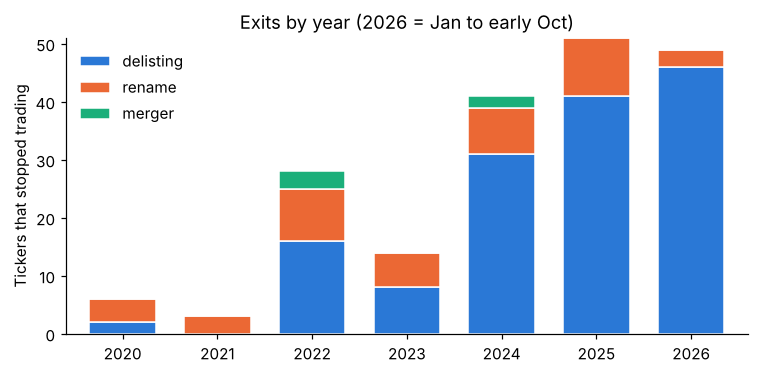

,delisting,rename,merger
year,,,
2020,2,4,0
2021,0,3,0
2022,16,9,3
2023,8,6,0
2024,31,8,2
2025,41,10,0
2026,46,3,0


In [2]:
exits = q('''SELECT year(last_date) AS year,
                    COUNT(*) FILTER (WHERE exit_type = 'delisting') AS delisting,
                    COUNT(*) FILTER (WHERE exit_type = 'rename')    AS rename,
                    COUNT(*) FILTER (WHERE exit_type = 'merger')    AS merger
             FROM lifetimes WHERE stopped GROUP BY 1 ORDER BY 1''').set_index('year')

fig, ax = plt.subplots(figsize=(7, 3.5))
exits.plot.bar(stacked=True, ax=ax, color=[BLUE, '#eb6834', '#1baf7a'], width=0.7, rot=0, edgecolor='white')
ax.set_xlabel('')
ax.set_ylabel('Tickers that stopped trading')
ax.set_title('Exits by year (2026 = Jan to early Oct)')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('figures/exits_by_year.png', dpi=150)
plt.show()
exits

### Trading picks up before a delisting

Average daily dollar volume in a token's last 30 days, divided by the 60 days before that.
Delisted tokens trade more at the end, which is why the model uses features lagged by 30 days.

In [3]:
q('''WITH d AS (
       SELECT l.symbol, l.exit_type,
              AVG(p.close * p.volume) FILTER (WHERE p.ts > l.last_date - 30) AS last_30d,
              AVG(p.close * p.volume) FILTER (WHERE p.ts <= l.last_date - 30 AND p.ts > l.last_date - 90) AS prior_60d
       FROM lifetimes l JOIN prices p USING (symbol)
       WHERE l.stopped
       GROUP BY 1, 2)
     SELECT exit_type, COUNT(*) AS tickers,
            ROUND(MEDIAN(last_30d / prior_60d), 2) AS median_ratio,
            ROUND(100 * AVG(CASE WHEN last_30d > prior_60d THEN 1 ELSE 0 END), 1) AS pct_higher
     FROM d GROUP BY 1 ORDER BY 2 DESC''')

,exit_type,tickers,median_ratio,pct_higher
0,delisting,144,1.51,68.8
1,rename,43,1.11,55.8
2,merger,5,0.69,0.0


### Look-ahead check

Recompute two panel features in pandas for 200 random rows, using only prices strictly before each cutoff.

In [4]:
prices = q('SELECT symbol, ts, close, close * volume AS dv FROM prices')
prices['ts'] = pd.to_datetime(prices['ts'])
by_symbol = dict(tuple(prices.groupby('symbol')))

sample = panel.dropna(subset=['log_dv30_lag30']).sample(200, random_state=1)
mismatches = 0
for _, r in sample.iterrows():
    for lag in [0, 30]:
        cutoff = r.month_start - pd.Timedelta(days=lag)
        past = by_symbol[r.symbol]
        past = past[past.ts < cutoff]
        window = past[past.ts >= past.ts.max() - pd.Timedelta(days=29)]
        log_dv30 = np.log(window.dv.mean() + 1)
        drawdown = past.close.iloc[-1] / past.close.max() - 1
        mismatches += abs(log_dv30 - r[f'log_dv30_lag{lag}']) > 1e-9
        mismatches += abs(drawdown - r[f'drawdown_lag{lag}']) > 1e-9
print(f'{mismatches} mismatches out of {len(sample) * 4} recomputed values')

0 mismatches out of 800 recomputed values


## 2. Cox model

Five features, each winsorized at 1%/99% and standardized, so a hazard ratio is per one standard deviation.

In [5]:
FEATS = ['log_dv30_lag30', 'dv_trend_lag30', 'vol30_lag30', 'ret90_lag30', 'drawdown_lag30']
X = ['volume', 'volume_trend', 'volatility', 'return_90d', 'drawdown']
COLS = ['asset_id', 'start_age', 'stop_age', 'event']


def prep(data, feats=FEATS, ref=None):
    # winsorize at 1%/99% and standardize; cutoffs, mean and SD come from `ref` (the training set out of sample)
    ref = data if ref is None else ref
    d = data.dropna(subset=feats).rename(columns=dict(zip(feats, X)))
    r = ref.dropna(subset=feats).rename(columns=dict(zip(feats, X)))
    lo, hi = r[X].quantile(0.01), r[X].quantile(0.99)
    r = r[X].clip(lo, hi, axis=1)
    d[X] = (d[X].clip(lo, hi, axis=1) - r.mean()) / r.std()
    d['event'] = d['event'].astype(int)
    return d


def fit(d, features):
    return CoxTimeVaryingFitter().fit(d[COLS + features], id_col='asset_id', event_col='event',
                                      start_col='start_age', stop_col='stop_age')


df = prep(panel)
cox = fit(df, X)
summary = cox.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
summary.columns = ['HR', 'lower', 'upper', 'p']
summary.round(3)

,HR,lower,upper,p
covariate,,,,
volume,0.270,0.197,0.368,0.000
volume_trend,1.315,1.031,1.678,0.028
volatility,1.692,1.341,2.135,0.000
return_90d,0.471,0.357,0.622,0.000
drawdown,1.345,0.935,1.936,0.110


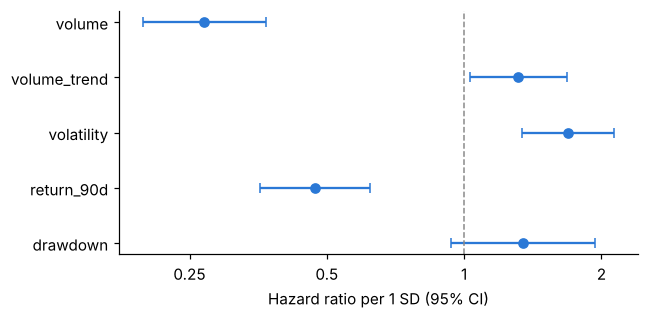

In [6]:
s = summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(s.HR, range(len(s)), xerr=[s.HR - s.lower, s.upper - s.HR], fmt='o', color=BLUE, capsize=3)
ax.axvline(1, color=GREY, lw=1, ls='--')
ax.set_yticks(range(len(s)))
ax.set_yticklabels(s.index)
ax.set_xscale('log')
ax.minorticks_off()
ax.set_xticks([0.25, 0.5, 1, 2])
ax.set_xticklabels(['0.25', '0.5', '1', '2'])
ax.set_xlabel('Hazard ratio per 1 SD (95% CI)')
plt.tight_layout()
plt.savefig('figures/hazard_ratios.png', dpi=150)
plt.show()

Low volume is by far the strongest signal: one standard deviation more volume cuts the delisting hazard by about 70%.
Weak 90-day returns and high volatility also raise the hazard.

## 3. Proportional hazards check

Interact every feature with log(age). If the effects were constant over a token's life, these terms would be zero.

In [7]:
df['log_age'] = np.log(df['start_age']) - np.log(df['start_age']).mean()
XA = [x + '_x_age' for x in X]
for x in X:
    df[x + '_x_age'] = df[x] * df['log_age']

cox_age = fit(df, X + XA)
lr = 2 * (cox_age.log_likelihood_ - cox.log_likelihood_)
print(f'LR = {lr:.2f}, df = {len(XA)}, p = {stats.chi2.sf(lr, len(XA)):.4f}')
cox_age.summary.loc[XA, ['exp(coef)', 'p']].round(3)

LR = 25.73, df = 5, p = 0.0001


,exp(coef),p
covariate,,
volume_x_age,0.809,0.478
volume_trend_x_age,0.831,0.499
volatility_x_age,2.423,0.002
return_90d_x_age,1.026,0.936
drawdown_x_age,0.306,0.005


Volatility and drawdown change with age. A simpler way to show it: let their effects differ for tokens younger than two years.
The 1- and 3-year cutoffs check that the result does not depend on the choice of two years.

In [8]:
def hr(model, terms):
    # hazard ratio and 95% CI of a sum of coefficients
    b = model.params_
    V = pd.DataFrame(np.asarray(model.variance_matrix_), index=b.index, columns=b.index)
    est = b[terms].sum()
    se = np.sqrt(V.loc[terms, terms].values.sum())
    return f'{np.exp(est):.2f} ({np.exp(est - 1.96 * se):.2f}–{np.exp(est + 1.96 * se):.2f})'


def add_young(d, years=2):
    d['young'] = (d['start_age'] < 365 * years).astype(int)
    d['volatility_x_young'] = d['volatility'] * d['young']
    d['drawdown_x_young'] = d['drawdown'] * d['young']
    return d


XY = X + ['volatility_x_young', 'drawdown_x_young']
rows = {}
for years in [1, 2, 3]:
    d = add_young(df.copy(), years)
    m = fit(d, XY)
    rows[f'{years} year'] = {
        'young events': int(d.loc[d.young == 1, 'event'].sum()),
        'volatility, older': hr(m, ['volatility']),
        'volatility, young': hr(m, ['volatility', 'volatility_x_young']),
        'drawdown, older': hr(m, ['drawdown']),
        'drawdown, young': hr(m, ['drawdown', 'drawdown_x_young']),
    }
pd.DataFrame(rows)

,1 year,2 year,3 year
young events,3,17,36
"volatility, older",1.71 (1.35–2.16),1.85 (1.46–2.36),1.99 (1.55–2.57)
"volatility, young",1.25 (0.32–4.91),0.89 (0.46–1.70),1.07 (0.69–1.67)
"drawdown, older",1.20 (0.80–1.81),0.79 (0.45–1.41),0.71 (0.37–1.38)
"drawdown, young",3.92 (1.04–14.69),3.75 (2.07–6.78),2.72 (1.67–4.44)


For young tokens, trading close to the all-time high is the warning sign (`drawdown` = price / running max − 1, so a higher value means closer to the peak); for older tokens, high volatility is.
The pattern holds with a 2- or 3-year cutoff. With a 1-year cutoff only 3 young tokens were delisted, too few to say anything.

## 4. Robustness

The two-year model, re-estimated under different choices.

In [9]:
def two_year_model(data, feats=FEATS):
    d = add_young(prep(data, feats))
    m = fit(d, XY)
    return pd.Series({
        'volume': hr(m, ['volume']),
        'volume_trend': hr(m, ['volume_trend']),
        'return_90d': hr(m, ['return_90d']),
        'volatility, older': hr(m, ['volatility']),
        'volatility, young': hr(m, ['volatility', 'volatility_x_young']),
        'drawdown, older': hr(m, ['drawdown']),
        'drawdown, young': hr(m, ['drawdown', 'drawdown_x_young']),
        'events': int(d['event'].sum()),
    })


LAG0 = [f.replace('lag30', 'lag0') for f in FEATS]
with_pairs = panel.assign(event=(panel.exit_type == 'delisting') &
                                (pd.to_datetime(panel.last_date).dt.to_period('M') == panel.month_start.dt.to_period('M')))
review = panel.loc[panel.needs_review == 1, 'asset_id'].unique()

robust = pd.DataFrame({
    'main': two_year_model(panel),
    'incl. USDT-pair removals': two_year_model(with_pairs),
    'drop needs_review': two_year_model(panel[~panel.asset_id.isin(review)]),
    'lag0 features': two_year_model(panel, LAG0),
    'drop left-truncated': two_year_model(panel[~panel.asset_left_truncated]),
})
robust.to_csv('results_robustness.csv')
robust

,main,incl. USDT-pair removals,drop needs_review,lag0 features,drop left-truncated
volume,0.28 (0.21–0.39),0.32 (0.24–0.44),0.29 (0.21–0.40),0.24 (0.17–0.33),0.30 (0.21–0.42)
volume_trend,1.27 (0.99–1.63),1.18 (0.93–1.51),1.24 (0.97–1.60),1.55 (1.20–1.99),1.22 (0.93–1.60)
return_90d,0.45 (0.34–0.60),0.51 (0.39–0.67),0.47 (0.35–0.62),0.34 (0.27–0.44),0.46 (0.34–0.62)
"volatility, older",1.85 (1.46–2.36),1.81 (1.43–2.30),1.85 (1.45–2.36),2.60 (2.13–3.18),1.84 (1.40–2.43)
"volatility, young",0.89 (0.46–1.70),0.77 (0.42–1.42),0.87 (0.44–1.71),1.48 (0.92–2.36),0.97 (0.49–1.94)
"drawdown, older",0.79 (0.45–1.41),0.71 (0.40–1.27),0.78 (0.44–1.39),0.98 (0.56–1.72),0.79 (0.41–1.53)
"drawdown, young",3.75 (2.07–6.78),2.44 (1.40–4.25),3.38 (1.80–6.34),2.97 (1.55–5.66),4.00 (2.18–7.34)
events,136,144,134,136,110


The signs and rough sizes hold in every version. With unlagged features (`lag0`) the effects get larger,
because they partly pick up trading after the announcement.

## 5. Out of sample

Fit on months before 2025 and score every token-month from 2025 on. Winsorizing and standardizing use training data only.
Within each test month, tokens are ranked by predicted risk.

The age interactions were found on the full sample, which includes the test period. Before 2025 alone the
proportional hazards test finds nothing (next cell), so the five-feature model without interactions is the fair out-of-sample result.

In [10]:
SPLIT = pd.Timestamp('2025-01-01')
before = panel[panel.month_start < SPLIT]
train = prep(before)
test = prep(panel[panel.month_start >= SPLIT], ref=before)
print(f'train: {len(train):,} rows, {train.event.sum()} events; test: {len(test):,} rows, {test.event.sum()} events')

t = train.copy()
t['log_age'] = np.log(t['start_age']) - np.log(t['start_age']).mean()
for x in X:
    t[x + '_x_age'] = t[x] * t['log_age']
lr = 2 * (fit(t, X + XA).log_likelihood_ - fit(t, X).log_likelihood_)
print(f'PH test, before 2025 only: LR = {lr:.2f}, p = {stats.chi2.sf(lr, len(XA)):.2f}')

train: 15,758 rows, 49 events; test: 8,721 rows, 87 events
PH test, before 2025 only: LR = 3.13, p = 0.68


In [11]:
train, test = add_young(train), add_young(test)


def score(features):
    m = fit(train, features)
    s = test.copy()
    s['risk'] = m.predict_log_partial_hazard(s[features]).values
    s['rank'] = s.groupby('month_start')['risk'].rank(pct=True, ascending=False)
    caught = s.loc[s.event == 1, 'rank']
    return s, {'AUC': round(roc_auc_score(s.event, s.risk), 3),
               'top 10% catches': f'{caught.le(0.1).mean():.0%}',
               'top 20% catches': f'{caught.le(0.2).mean():.0%}'}


scored, main = score(X)
oos = pd.DataFrame({
    'volume only': score(['volume'])[1],
    'five features': main,
    'five features + age terms*': score(XY)[1],
}).T
oos

,AUC,top 10% catches,top 20% catches
volume only,0.697,30%,45%
five features,0.728,34%,54%
five features + age terms*,0.772,40%,57%


\* Age terms chosen using the full sample, so this row is optimistic.

The five-feature model adds to volume alone: each month's riskiest 10% of tokens contains about a third of the 2025–26 delistings.

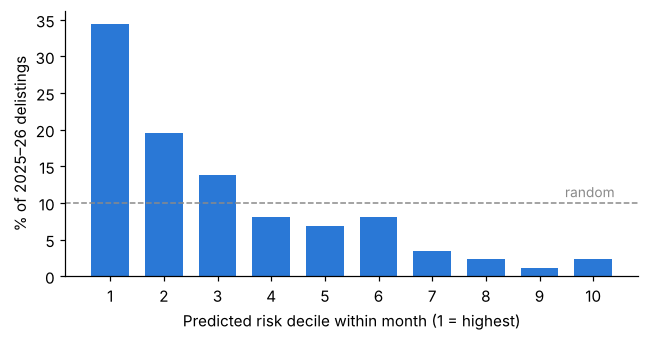

In [12]:
scored['decile'] = np.ceil(scored['rank'] * 10).astype(int)
share = scored.loc[scored.event == 1, 'decile'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(share.index, share.values, color=BLUE, width=0.7)
ax.axhline(10, color=GREY, lw=1, ls='--')
ax.text(10.4, 10.8, 'random', color=GREY, ha='right', fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Predicted risk decile within month (1 = highest)')
ax.set_ylabel('% of 2025–26 delistings')
plt.tight_layout()
plt.savefig('figures/oos_risk_deciles.png', dpi=150)
plt.show()

## Limitations

- Binance announces delistings in batches, so events on the same day are not independent; the confidence intervals are probably too narrow.
  lifelines' `CoxTimeVaryingFitter` has no clustered standard errors.
- 136 delistings over six years is a small number of events, especially for young tokens.
- Tokens Binance had already removed before the data was pulled are missing, so early years undercount delistings.